# 02 · Point-in-time features

A fraud model scores a payment the moment it arrives, so a feature may only use what was known
then: the customer's **earlier** transactions. Every feature here is a SQL window over strictly
earlier rows (`sql/10_features.sql`): the customer's velocity, the amount against their own
history, and changes in email or device since their last payment. None uses a fraud label,
because chargebacks arrive weeks after the payment.

The check that matters is mechanical: delete everything after a cutoff, rebuild the features, and
confirm that no feature of an earlier transaction changed.

In [1]:
import sys
from pathlib import Path


def _project_root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "fraudrisk" / "__init__.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


sys.path.insert(0, str(_project_root() / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

from fraudrisk import data, features
from fraudrisk.records import show_verdict, write_metrics

SOURCE = data.source()
con = data.connect()
features.build(con)
F = features.frame(con)
print(SOURCE, F.shape)

real (590540, 21)


## 1. Can any feature see the future?

Three cutoffs inside the data. For each, the features are rebuilt with every later transaction
deleted and compared, transaction by transaction, with the features built on all the data.

In [2]:
RAW_COLS = ["TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD", "card1", "addr1", "D1",
            "P_emaildomain", "DeviceType", "DeviceInfo", "dist1", "id_01"]
raw = con.sql(f"SELECT {', '.join(RAW_COLS)} FROM tx").df()
cutoffs = list(raw["TransactionDT"].quantile([0.25, 0.5, 0.75]))
pit = features.point_in_time_violations(raw, cutoffs)
del raw
violations = int(pit[features.FEATURES].to_numpy().sum())
print(f"features changed by deleting the future: {violations} values in {int(pit['transactions_checked'].sum()):,} checks")
pit[["cutoff", "transactions_checked"]].assign(changed_values=pit[features.FEATURES].sum(axis=1))

features changed by deleting the future: 0 values in 885,810 checks


,cutoff,transactions_checked,changed_values
0,3027057.75,147635,0
1,7306527.50,295270,0
2,11246620.00,442905,0


## 2. How much history is there?

A model can only use a customer's history if they have one. New customers are where the
provider's fields and the device data have to carry the score.

In [3]:
train = F[F["split"] == "train"]
history = pd.DataFrame({
    "share of transactions": [(train["cust_prior_tx"] == 0).mean(), (train["cust_prior_tx"] > 0).mean()],
    "fraud rate": [train.loc[train["cust_prior_tx"] == 0, "isFraud"].mean(), train.loc[train["cust_prior_tx"] > 0, "isFraud"].mean()],
}, index=["first transaction of customer", "returning customer"])
history

,share of transactions,fraud rate
first transaction of customer,0.398141,0.026393
returning customer,0.601859,0.041059


## 3. Signal in each feature, on the training months only

Single-feature ROC AUC (oriented so that 0.5 is no signal and higher is better), and the fraud
rate in the feature's top decile against its overall rate. Missing values are scored as the
median, so a feature is not credited for being missing.

In [4]:
def single_auc(x, y):
    x = pd.to_numeric(x, errors="coerce").astype(float)
    x = x.fillna(x.median())
    if x.nunique() < 2:
        return np.nan
    a = roc_auc_score(y, x)
    return max(a, 1 - a)


def top_decile_lift(x, y):
    x = pd.to_numeric(x, errors="coerce").astype(float)
    ok = x.notna()
    if ok.sum() < 20 or x[ok].nunique() < 2:
        return np.nan
    q = x[ok].rank(pct=True)
    hi = y[ok][q >= 0.9].mean()
    lo = y[ok][q <= 0.1].mean()
    return max(hi, lo) / y[ok].mean()


y = train["isFraud"].astype(int)
signal = pd.DataFrame({
    "auc": {c: single_auc(train[c], y) for c in features.FEATURES},
    "top_decile_lift": {c: top_decile_lift(train[c], y) for c in features.FEATURES},
    "missing": {c: train[c].isna().mean() for c in features.FEATURES},
}).sort_values("auc", ascending=False)
signal.round(3)

,auc,top_decile_lift,missing
cust_tx_7d,0.644,2.505,0.000
hours_since_prev,0.644,2.097,0.398
cust_tx_24h,0.624,2.171,0.000
cust_amt_24h,0.619,1.886,0.000
cust_prior_tx,0.582,1.786,0.000
cust_tx_1h,0.580,2.288,0.000
amount_cents,0.558,0.658,0.000
card_tx_1h,0.543,1.102,0.000
cust_mean_amt,0.533,1.644,0.398
card_tx_24h,0.526,0.854,0.000


## 4. Figure

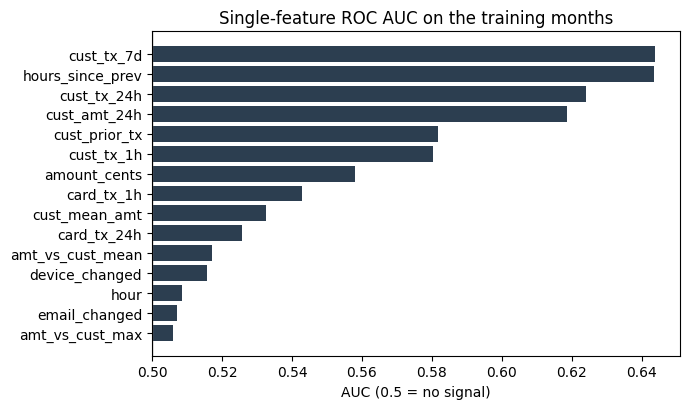

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.2))
s = signal.sort_values("auc")
ax.barh(s.index, s["auc"] - 0.5, left=0.5, color="#2c3e50")
ax.axvline(0.5, color="grey", lw=1)
ax.set(title="Single-feature ROC AUC on the training months", xlabel="AUC (0.5 = no signal)")
fig.tight_layout()
data.savefig(fig, "02_feature_signal", SOURCE)

## 5. Save for phase 3 (real data only; never committed)

In [6]:
if SOURCE == "real":
    out = data.PARQUET.parent / "features.parquet"
    con.execute(f"COPY (SELECT * FROM features ORDER BY TransactionDT, TransactionID) TO '{out.as_posix()}' (FORMAT parquet)")
    print("wrote", out.relative_to(data.ROOT).as_posix())

record = {
    "features": features.FEATURES,
    "point_in_time": {"cutoffs": len(cutoffs), "checks": int(pit["transactions_checked"].sum()), "changed_values": violations},
    "history": {k: {"share": float(r["share of transactions"]), "fraud_rate": float(r["fraud rate"])} for k, r in history.iterrows()},
    "signal": {k: {kk: (None if pd.isna(vv) else float(vv)) for kk, vv in r.items()} for k, r in signal.iterrows()},
}
write_metrics("02_features", record, SOURCE)

wrote data/interim/features.parquet


In [7]:
top = signal.head(3)
h = record["history"]
show_verdict(
    "Verdict: phase 2, point-in-time features",
    [
        f"**No feature can see the future**: rebuilding with everything after {len(cutoffs)} cutoffs deleted changed "
        f"{violations} of {record['point_in_time']['checks'] * len(features.FEATURES):,} feature values."
        if violations == 0 else f"**{violations} feature values changed when the future was deleted**: fix before modelling.",
        f"**{h['first transaction of customer']['share']:.0%} of training transactions are a customer's first**, with fraud rate "
        f"{h['first transaction of customer']['fraud_rate']:.1%} against {h['returning customer']['fraud_rate']:.1%} for returning "
        "customers; history features can only help the rest.",
        "**Strongest single features**: " + "; ".join(f"`{k}` AUC {r['auc']:.2f}" for k, r in top.iterrows())
        + ". Phase 3 combines them with the provider's fields.",
    ],
    "Phase 3 trains rules, logistic regression and gradient boosting on the training months and compares them on later months.",
)

### Verdict: phase 2, point-in-time features

1. **No feature can see the future**: rebuilding with everything after 3 cutoffs deleted changed 0 of 13,287,150 feature values.
2. **40% of training transactions are a customer's first**, with fraud rate 2.6% against 4.1% for returning customers; history features can only help the rest.
3. **Strongest single features**: `cust_tx_7d` AUC 0.64; `hours_since_prev` AUC 0.64; `cust_tx_24h` AUC 0.62. Phase 3 combines them with the provider's fields.

**Next:** Phase 3 trains rules, logistic regression and gradient boosting on the training months and compares them on later months.